# 08 – Model Evaluation & Explainability

## Objective
The objective of this notebook is to evaluate the previously trained Netflix customer churn prediction model and understand which customer features influence its predictions.

## Key Activities
1. Load the saved churn prediction model.
2. Load the feature-engineered customer dataset.
3. Load the selected prediction threshold.
4. Evaluate model performance using classification metrics.
5. Analyze the confusion matrix and ROC curve.
6. Understand important features using model explainability techniques.
7. Summarize model performance and business implications.

## Methodology
The saved Logistic Regression pipeline from the churn prediction notebook will be evaluated using the available customer dataset and the selected classification threshold.

## Important Note
This notebook evaluates the existing trained model. It does not train a new model. Evaluation results must be interpreted with the limitations of the original train-test split and threshold selection in mind.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import json

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import joblib

# Load the feature-engineered dataset
df = pd.read_csv('/content/netflix_feature_engineered.csv')

# Load the trained model using joblib
model = joblib.load('/content/netflix_churn_model.pkl')

# Load the selected threshold
with open('/content/netflix_churn_threshold.json', 'r') as file:
    threshold_data = json.load(file)

threshold = threshold_data

print("Dataset shape:", df.shape)
print("Model loaded successfully!")
print("Threshold data:", threshold_data)
print("\nModel pipeline steps:", model.named_steps.keys())

Dataset shape: (8000, 36)
Model loaded successfully!
Threshold data: {'model': 'Logistic Regression', 'churn_threshold': 0.6}

Model pipeline steps: dict_keys(['preprocessor', 'classifier'])


## Step 3 – Recreate the Test Dataset

The original dataset is divided into training and testing sets using an 80:20 split. Stratified sampling and random state 42 are used to maintain consistency with the original model training.

The test dataset is used to evaluate the saved churn prediction model.

In [4]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=[
    'customer_id',
    'subscription_start_date',
    'churned'
])

y = df['churned']

# Recreate the original 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("\nTest target distribution:")
print(y_test.value_counts())

Training data shape: (6400, 33)
Testing data shape: (1600, 33)

Test target distribution:
churned
0    1202
1     398
Name: count, dtype: int64


## Step 4 – Generate Model Predictions

The saved Logistic Regression pipeline is used to predict churn probabilities for the test dataset.

A probability threshold of 0.60 is applied:
- Probability greater than or equal to 0.60: Likely to Churn (1)
- Probability below 0.60: Not Likely to Churn (0)

The predicted results are compared with the actual churn labels.

In [5]:
# Predict churn probabilities
y_probability = model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
y_pred = (y_probability >= threshold_data['churn_threshold']).astype(int)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

print("\nPredicted customer distribution:")
print(pd.Series(y_pred).value_counts().sort_index())

print("\nFirst 10 actual values:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10].tolist())

Predictions generated successfully!
Number of predictions: 1600

Predicted customer distribution:
0    1142
1     458
Name: count, dtype: int64

First 10 actual values:
[1, 1, 0, 1, 0, 1, 0, 1, 0, 1]

First 10 predicted values:
[1, 0, 1, 1, 0, 1, 0, 1, 0, 1]


## Step 5 – Model Performance Evaluation

The model is evaluated using five performance metrics:

- Accuracy: Overall percentage of correct predictions.
- Precision: How many customers predicted to churn actually churned.
- Recall: How many actual churned customers the model identified.
- F1-score: Balance between precision and recall.
- ROC-AUC: How well the model distinguishes churned and non-churned customers across different thresholds.

In [6]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

# Display results
evaluation_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Score': [accuracy, precision, recall, f1, roc_auc]
})

print("MODEL PERFORMANCE RESULTS")
display(evaluation_results.round(4))

MODEL PERFORMANCE RESULTS


,Metric,Score
0,Accuracy,0.7675
1,Precision,0.5284
2,Recall,0.6080
3,F1-Score,0.5654
4,ROC-AUC,0.7891


## Step 6 – Confusion Matrix

A confusion matrix compares actual customer churn labels with the model's predictions.

It contains four outcomes:
- True Negative (TN): Correctly predicted a customer would not churn.
- False Positive (FP): Predicted churn, but the customer did not churn.
- False Negative (FN): Missed a customer who actually churned.
- True Positive (TP): Correctly identified a customer who churned.

This helps us understand the types of mistakes made by the model.

CONFUSION MATRIX
[[986 216]
 [156 242]]


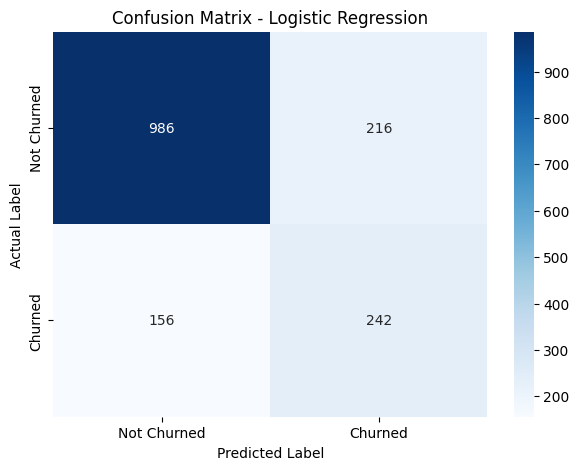

In [7]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("CONFUSION MATRIX")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Churned', 'Churned'],
    yticklabels=['Not Churned', 'Churned']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

### Confusion Matrix – Key Findings

The confusion matrix shows the following results:

- 986 customers were correctly predicted as not churned.
- 242 customers were correctly identified as churned.
- 216 customers were incorrectly predicted as churned.
- 156 customers who actually churned were missed by the model.

The model identifies a useful number of customers at risk of leaving, but some churners remain undetected. Retention teams should use predictions as a prioritization tool rather than treating them as certain outcomes.

## Step 7 – ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve evaluates the model's ability to distinguish between churned and non-churned customers at different classification thresholds.

The Area Under the Curve (ROC-AUC) summarizes this performance. A higher ROC-AUC indicates better separation between the two classes.

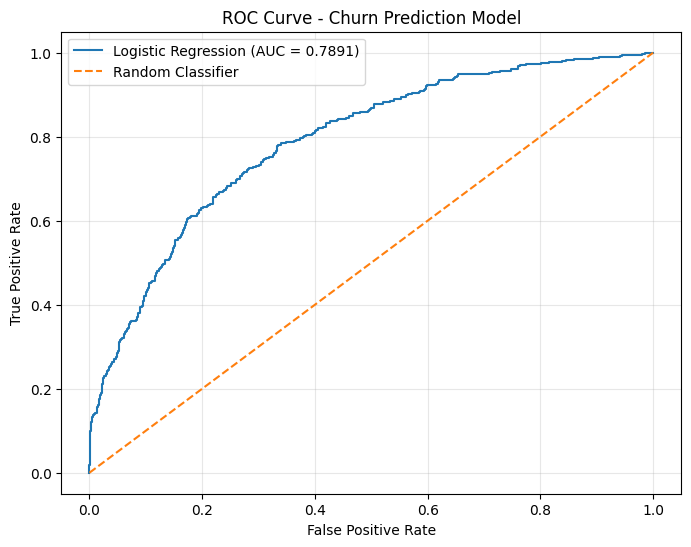

ROC-AUC Score: 0.7891


In [8]:
# Calculate ROC curve points
fpr, tpr, thresholds = roc_curve(y_test, y_probability)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.4f})'
)

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Churn Prediction Model')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("ROC-AUC Score:", round(roc_auc, 4))

### ROC Curve – Key Findings

The Logistic Regression model achieved a ROC-AUC score of 0.7891.

The ROC curve stays above the random classifier line, indicating that the model has a reasonable ability to distinguish between customers who churn and those who do not.

This suggests that the model has useful predictive ability, although further improvements may be needed before using it in a real business environment.

## Step 8 – Feature Importance and Model Explainability

Feature importance helps us understand which input variables influence the model's churn predictions.

Since Logistic Regression is used, we examine its coefficients:

- Positive coefficients indicate a higher predicted likelihood of churn.
- Negative coefficients indicate a lower predicted likelihood of churn.
- Larger absolute coefficient values indicate stronger relationships within the fitted model.

These relationships do not prove that a feature causes customer churn.

In [9]:
# Extract the trained Logistic Regression classifier
classifier = model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = model.named_steps['preprocessor'].get_feature_names_out()

# Extract model coefficients
coefficients = classifier.coef_[0]

# Create a feature importance DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Sort by absolute coefficient value
importance_df['Absolute_Importance'] = importance_df['Coefficient'].abs()

importance_df = importance_df.sort_values(
    by='Absolute_Importance',
    ascending=False
)

print("TOP 15 FEATURES INFLUENCING CHURN")
display(importance_df.head(15).round(4))

TOP 15 FEATURES INFLUENCING CHURN


,Feature,Coefficient,Absolute_Importance
64,numerical__viewing_sessions,-0.8758,0.8758
14,categorical__country_Mexico,-0.3778,0.3778
80,numerical__has_support_tickets,-0.3392,0.3392
65,numerical__total_watch_minutes,-0.3291,0.3291
46,categorical__preferred_language_Polish,0.3160,0.3160
50,categorical__preferred_language_Unknown,-0.3026,0.3026
73,numerical__average_support_satisfaction,-0.2946,0.2946
60,numerical__failed_payment_count,0.2667,0.2667
58,numerical__subscription_tenure_days,-0.2565,0.2565
19,categorical__country_South Korea,0.2502,0.2502


## Step 9 – Feature Importance Visualization

A horizontal bar chart is used to visualize the top 15 features influencing churn predictions.

Positive coefficients are displayed on the right side, while negative coefficients are displayed on the left side. This makes it easier to compare the direction and strength of each feature's relationship with churn.

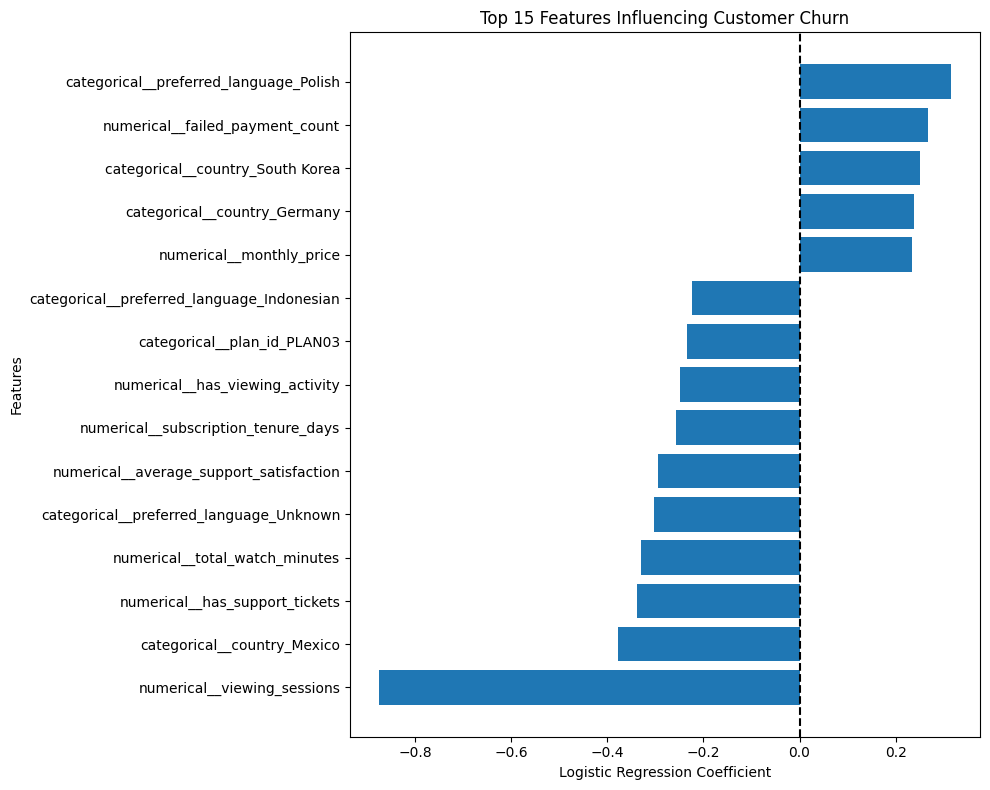

In [10]:
# Select the top 15 features
top_features = importance_df.head(15).sort_values(
    by='Coefficient'
)

# Plot feature coefficients
plt.figure(figsize=(10, 8))

plt.barh(
    top_features['Feature'],
    top_features['Coefficient']
)

plt.axvline(x=0, linestyle='--', color='black')

plt.xlabel('Logistic Regression Coefficient')
plt.ylabel('Features')
plt.title('Top 15 Features Influencing Customer Churn')

plt.tight_layout()
plt.show()

### Feature Importance – Key Findings

The feature importance analysis highlights several variables associated with customer churn.

1. Viewing sessions has the strongest negative coefficient, suggesting that more active customers tend to have lower predicted churn risk.
2. Failed payment count has a positive coefficient, indicating that payment difficulties are associated with higher churn risk.
3. Monthly price has a positive relationship with predicted churn.
4. Average support satisfaction has a negative relationship with predicted churn.
5. Subscription tenure also has a negative coefficient, suggesting that longer-tenure customers tend to have lower predicted churn risk.

These findings can help the business identify customer engagement, payment, pricing, and service factors worth investigating.

Note: Logistic Regression coefficients show associations within the fitted model. They do not establish causation, and categorical coefficients are relative to their reference categories.

# Final Business Findings and Recommendations

## Key Findings

1. The Logistic Regression model achieved 76.75% accuracy and a ROC-AUC score of 0.7891.
2. At the selected threshold of 0.60, the model identified 242 actual churners and missed 156.
3. Viewing sessions showed the strongest negative relationship with predicted churn.
4. Failed payment count and monthly price showed positive relationships with predicted churn.
5. Average support satisfaction and subscription tenure showed negative relationships with predicted churn.

## Business Recommendations

1. **Improve Customer Engagement:** Identify customers with low viewing activity and recommend relevant content.
2. **Monitor Payment Issues:** Help customers resolve failed payments through reminders and payment support.
3. **Review Pricing:** Study customer feedback and cancellation reasons to identify pricing concerns.
4. **Improve Customer Support:** Monitor satisfaction scores and address recurring customer complaints.
5. **Use Churn Predictions:** Prioritize high-risk customers for retention campaigns and monitor campaign outcomes.

## Model Limitations

- The model does not guarantee that a customer will churn.
- Some churned customers are missed, while some non-churned customers are incorrectly flagged.
- The classification threshold was selected using the original test set, so these results are not an independent final validation.
- Feature coefficients indicate associations, not causes.
- The dataset may not represent all real-world customer behavior.

## Conclusion

This project evaluated a Logistic Regression model for predicting Netflix customer churn. The evaluation included classification metrics, a confusion matrix, an ROC curve, and coefficient-based feature analysis.

The results show that the model can help identify customers who may be at risk of leaving. The findings also highlight customer engagement, payment behavior, pricing, and support satisfaction as useful areas for further business investigation.